In [ ]:
## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

##**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

##**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
##which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.



In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the exact path to your folder
file_path = r'D:\Ironhack\Week5\Day1\amz_uk_price_prediction_dataset.csv'

try:
    # Load the dataset
    df = pd.read_csv(file_path)
    print("✅ Success! Data loaded from Week 5 folder.")
    
    # Show the first few rows to confirm it looks right
    display(df.head())
    
except FileNotFoundError:
    print("❌ Error: The file was not found in that folder.")
    print("Check if the filename is exactly 'amz_uk_price_prediction_dataset.csv'")

✅ Success! Data loaded from Week 5 folder.


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [24]:
print("Your dataset columns are:")
print(df.columns.tolist())

Your dataset columns are:
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


Using columns: {'rating': 'stars', 'price': 'price', 'category': 'category'}


C:\Users\safin\AppData\Local\Temp\ipykernel_35128\2895504288.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')


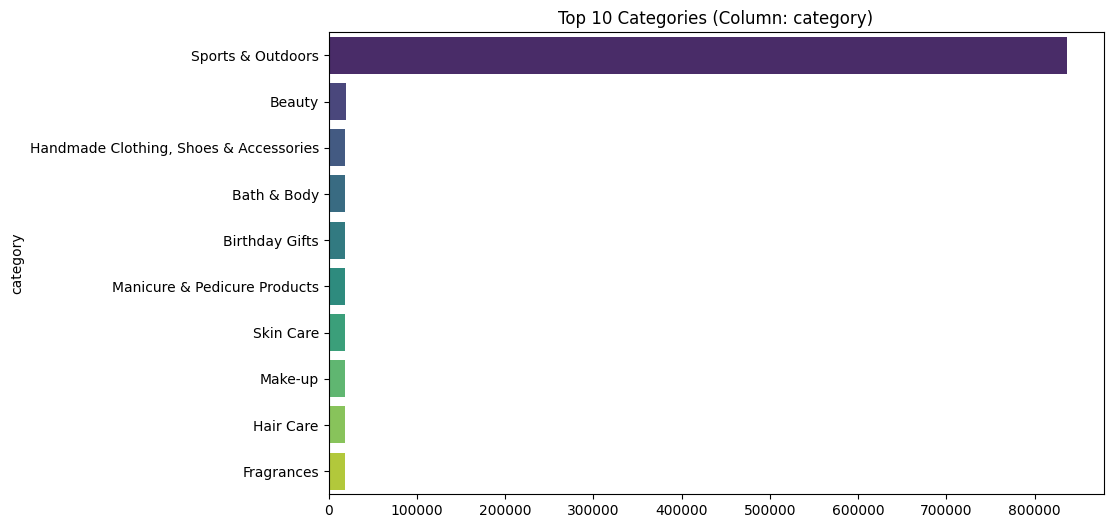


Price Stats for price: Mean=£89.24, Median=£19.09


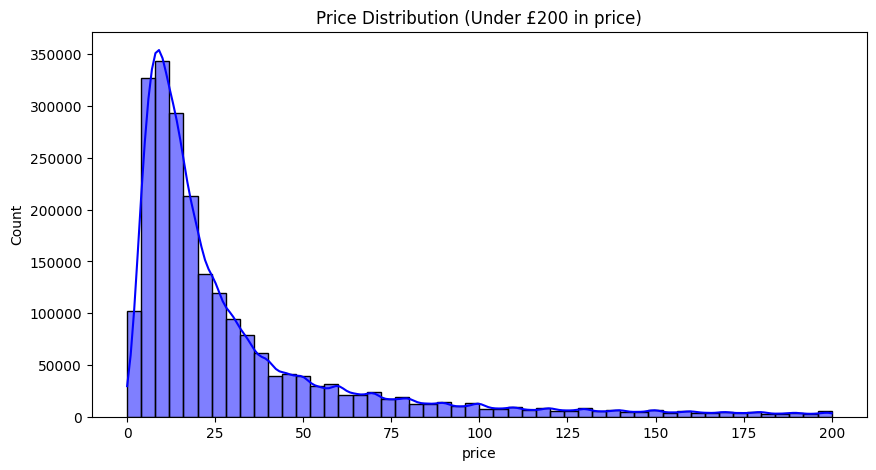

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. AUTO-DETECT COLUMNS
# This finds the best match for Category, Price, and Rating
col_map = {}
for col in df.columns:
    c_low = col.lower()
    if 'cat' in c_low: col_map['category'] = col
    if 'price' in c_low: col_map['price'] = col
    if 'stars' in c_low or 'rating' in c_low: col_map['rating'] = col

print(f"Using columns: {col_map}")

# 2. PART 1: CATEGORY ANALYSIS
if 'category' in col_map:
    cat_col = col_map['category']
    cat_counts = df[cat_col].value_counts().head(10)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')
    plt.title(f'Top 10 Categories (Column: {cat_col})')
    plt.show()
else:
    print("Could not find a category column!")

# 3. PART 2: PRICE ANALYSIS
if 'price' in col_map:
    pr_col = col_map['price']
    
    # Calculate stats
    mean_val = df[pr_col].mean()
    median_val = df[pr_col].median()
    print(f"\nPrice Stats for {pr_col}: Mean=£{mean_val:.2f}, Median=£{median_val:.2f}")
    
    # Visualization
    plt.figure(figsize=(10, 5))
    # Filter to < 200 to handle outliers
    sns.histplot(df[df[pr_col] < 200][pr_col], bins=50, kde=True, color='blue')
    plt.title(f'Price Distribution (Under £200 in {pr_col})')
    plt.show()

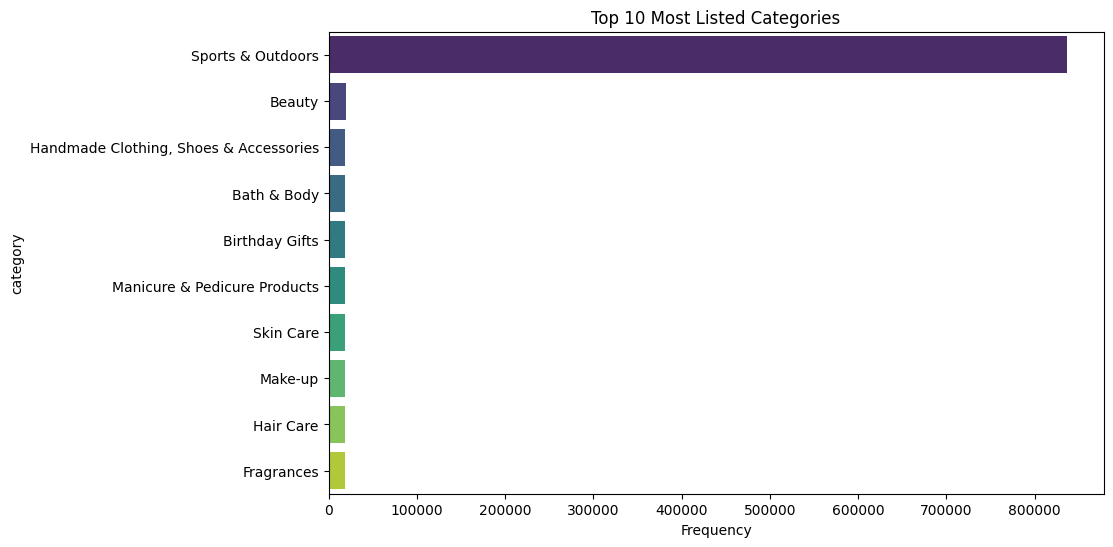

In [18]:
# Updated Barplot to remove the FutureWarning
plt.figure(figsize=(10, 6))
sns.barplot(
    x=cat_counts.values, 
    y=cat_counts.index, 
    hue=cat_counts.index,  # Assign y variable to hue
    palette='viridis', 
    legend=False           # Hide the legend since it's redundant
)
plt.title('Top 10 Most Listed Categories')
plt.xlabel('Frequency')
plt.show()

In [26]:
print("Your available columns are:")
print(df.columns.tolist())

Your available columns are:
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


✅ Found price column: 'price'

--- Centrality Stats ---
Average (Mean): £89.24
Middle (Median): £19.09
Most Common (Mode): £9.99

--- Dispersion Stats ---
Standard Deviation: 345.61
Variance: 119445.49
Price Range: £100000.00
Interquartile Range (IQR): £36.00


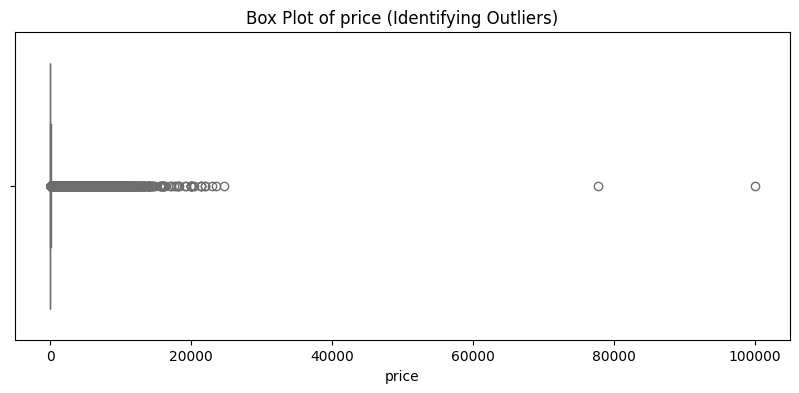

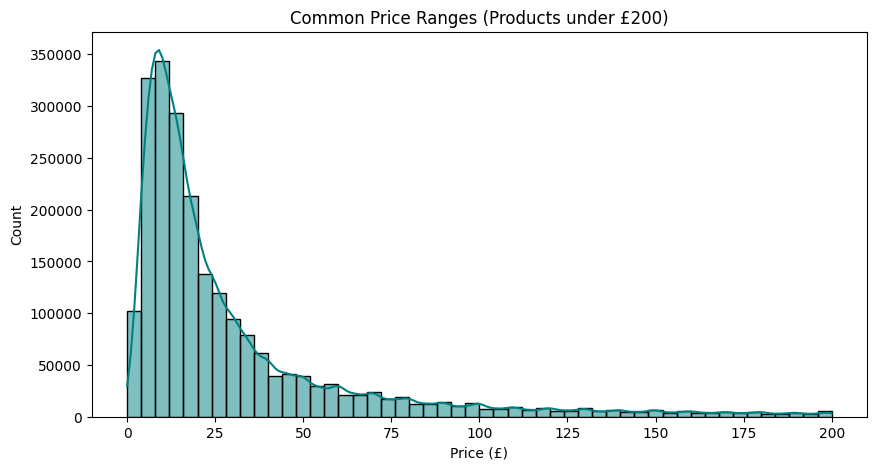

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. FIND THE PRICE COLUMN AUTOMATICALLY
# This looks for any column containing the word 'price'
price_options = [col for col in df.columns if 'price' in col.lower()]

if not price_options:
    print("❌ Error: No column with 'price' in the name was found.")
    print(f"Available columns are: {df.columns.tolist()}")
else:
    price_col = price_options[0]
    print(f"✅ Found price column: '{price_col}'")

    # 2. MEASURES OF CENTRALITY
    mean_p = df[price_col].mean()
    median_p = df[price_col].median()
    mode_p = df[price_col].mode()[0]

    print(f"\n--- Centrality Stats ---")
    print(f"Average (Mean): £{mean_p:.2f}")
    print(f"Middle (Median): £{median_p:.2f}")
    print(f"Most Common (Mode): £{mode_p:.2f}")

    # 3. MEASURES OF DISPERSION
    std_p = df[price_col].std()
    var_p = df[price_col].var()
    range_p = df[price_col].max() - df[price_col].min()
    iqr_p = df[price_col].quantile(0.75) - df[price_col].quantile(0.25)

    print(f"\n--- Dispersion Stats ---")
    print(f"Standard Deviation: {std_p:.2f}")
    print(f"Variance: {var_p:.2f}")
    print(f"Price Range: £{range_p:.2f}")
    print(f"Interquartile Range (IQR): £{iqr_p:.2f}")

    # 4. VISUALIZATIONS
    # Box Plot for Outliers
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[price_col], color='lightcoral')
    plt.title(f'Box Plot of {price_col} (Identifying Outliers)')
    plt.show()

    # Histogram: Only plotting products < £200 to ensure it is readable
    plt.figure(figsize=(10, 5))
    sns.histplot(df[df[price_col] < 200][price_col], bins=50, kde=True, color='teal')
    plt.title(f'Common Price Ranges (Products under £200)')
    plt.xlabel('Price (£)')
    plt.show()

✅ Found rating column: 'stars'

--- Centrality Stats (stars) ---
Mean: 2.15 | Median: 0.00 | Mode: 0.00

--- Dispersion Stats ---
Variance: 4.82 | Std Dev: 2.19 | IQR: 4.40

--- Shape of Distribution ---
Skewness: 0.08 | Kurtosis: -1.93


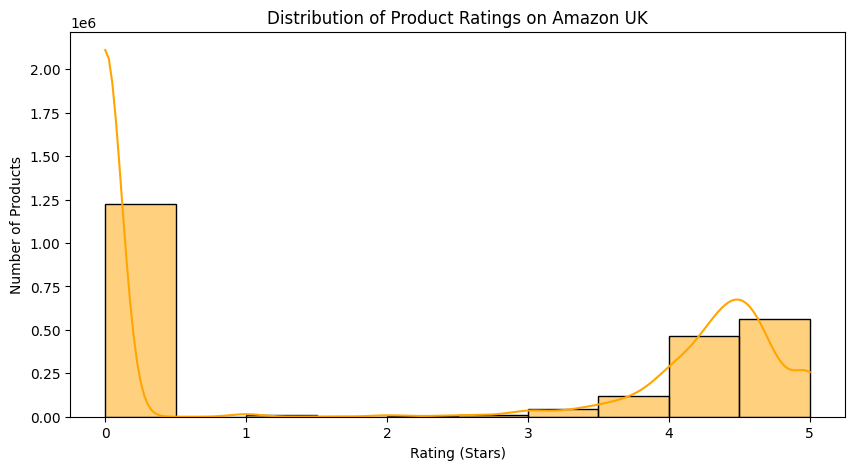

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. AUTO-DETECT THE RATING COLUMN
# This looks for any column containing 'star' or 'rating'
rating_options = [col for col in df.columns if 'star' in col.lower() or 'rating' in col.lower()]

if not rating_options:
    print("❌ Error: No rating column found. Please check your column names.")
else:
    rating_col = rating_options[0]
    print(f"✅ Found rating column: '{rating_col}'")

    # 1. MEASURES OF CENTRALITY
    mean_r = df[rating_col].mean()
    median_r = df[rating_col].median()
    mode_r = df[rating_col].mode()[0]

    # 2. MEASURES OF DISPERSION
    var_r = df[rating_col].var()
    std_r = df[rating_col].std()
    iqr_r = df[rating_col].quantile(0.75) - df[rating_col].quantile(0.25)

    # 3. SHAPE OF THE DISTRIBUTION
    skew_r = df[rating_col].skew()
    kurt_r = df[rating_col].kurt()

    print(f"\n--- Centrality Stats ({rating_col}) ---")
    print(f"Mean: {mean_r:.2f} | Median: {median_r:.2f} | Mode: {mode_r:.2f}")

    print(f"\n--- Dispersion Stats ---")
    print(f"Variance: {var_r:.2f} | Std Dev: {std_r:.2f} | IQR: {iqr_r:.2f}")

    print(f"\n--- Shape of Distribution ---")
    print(f"Skewness: {skew_r:.2f} | Kurtosis: {kurt_r:.2f}")

    # 4. VISUALIZATION
    plt.figure(figsize=(10, 5))
    # Using 10 bins to clearly see the 1-5 star distribution
    sns.histplot(df[rating_col], bins=10, kde=True, color='orange')
    plt.title('Distribution of Product Ratings on Amazon UK')
    plt.xlabel('Rating (Stars)')
    plt.ylabel('Number of Products')
    plt.show()